In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

SEQUENCE_LENGTH = 24
BATCH_SIZE = 32

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

In [8]:
csv_path = "../data/PRSA_Data_Aotizhongxin_20130301-20170228.csv"

df = pd.read_csv(csv_path)
df["timestamp"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("timestamp").reset_index(drop=True)

print("Ham veri:", df.shape)
print("Eksik PM2.5:", df["PM2.5"].isna().sum())

Ham veri: (35064, 19)
Eksik PM2.5: 925


In [9]:
# TEST 1 — Duplicate Timestamp

total_records = len(df)

duplicate_count = df["timestamp"].duplicated().sum()

print("Toplam kayıt:", total_records)
print("Tekrarlanan timestamp:", duplicate_count)

Toplam kayıt: 35064
Tekrarlanan timestamp: 0


In [10]:
# TEST 2 — Duplicate Rows

duplicate_rows = df.duplicated().sum()

print("Tekrarlanan tam satır:", duplicate_rows)

Tekrarlanan tam satır: 0


In [11]:
# TEST 3 — Conflicting Timestamps

conflicting_timestamps = (
    df.groupby("timestamp")["PM2.5"]
    .nunique(dropna=False)
    .gt(1)
    .sum()
)

print("Çelişkili timestamp:", conflicting_timestamps)

Çelişkili timestamp: 0


In [12]:
duplicate_report = pd.DataFrame({
    "Kontrol": [
        "Toplam kayıt",
        "Tekrarlanan timestamp",
        "Tekrarlanan tam satır",
        "Çelişkili timestamp"
    ],
    "Sonuç": [
        total_records,
        duplicate_count,
        duplicate_rows,
        conflicting_timestamps
    ]
})

display(duplicate_report)

,Kontrol,Sonuç
0,Toplam kayıt,35064
1,Tekrarlanan timestamp,0
2,Tekrarlanan tam satır,0
3,Çelişkili timestamp,0


In [13]:
df_sorted = df.sort_values("timestamp").reset_index(drop=True)

for i in range(len(df_sorted) - 24):

    block = df_sorted.iloc[i:i+25]

  
    if block["PM2.5"].isna().any():
        continue

 
    time_diffs = block["timestamp"].diff().dropna()

    if not (time_diffs == pd.Timedelta(hours=1)).all():
        continue

  
    window_a = block["timestamp"].iloc[:24]
    window_b = block["timestamp"].iloc[1:25]

    break

print("Window A:", window_a.iloc[0], "→", window_a.iloc[-1])
print("Window B:", window_b.iloc[0], "→", window_b.iloc[-1])

Window A: 2013-03-01 00:00:00 → 2013-03-01 23:00:00
Window B: 2013-03-01 01:00:00 → 2013-03-02 00:00:00


In [14]:
common_times = pd.Index(window_a).intersection(
    pd.Index(window_b)
)


overlap_count = len(common_times)


overlap_percentage = (overlap_count / len(window_a)) * 100

print("Ortak timestamp sayısı:", overlap_count)
print(f"Örtüşme yüzdesi: %{overlap_percentage:.2f}")

Ortak timestamp sayısı: 23
Örtüşme yüzdesi: %95.83


In [15]:
val_start_time = pd.Timestamp("2015-12-18 16:00")
test_start_time = pd.Timestamp("2016-07-24 20:00")

for i in range(24, len(df_sorted)):

    target_time = df_sorted.loc[i, "timestamp"]

    if target_time < val_start_time:
        continue

    if target_time >= test_start_time:
        break

    block = df_sorted.iloc[i-24:i+1]

    if block["PM2.5"].isna().any():
        continue

    time_diffs = block["timestamp"].diff().dropna()

    if not (time_diffs == pd.Timedelta(hours=1)).all():
        continue

    first_val_window = block
    break

else:
    first_val_window = None

if "first_val_window" not in locals() or first_val_window is None:
    raise ValueError("Geçerli validation penceresi bulunamadı.")

input_times = first_val_window["timestamp"].iloc[:-1]
target_time = first_val_window["timestamp"].iloc[-1]

print("İlk giriş zamanı:", input_times.iloc[0])
print("Son giriş zamanı:", input_times.iloc[-1])
print("Hedef zamanı:", target_time)

print(
    "Training döneminden gelen giriş sayısı:",
    (input_times < val_start_time).sum()
)

İlk giriş zamanı: 2015-12-17 20:00:00
Son giriş zamanı: 2015-12-18 19:00:00
Hedef zamanı: 2015-12-18 20:00:00
Training döneminden gelen giriş sayısı: 20


A) Pencerenin bir bölümü Training dönemindeki ölçümleri içeriyor mu?
    Cevap: Evet
    24 saatlik pencerenin:
    - 20 saati Training döneminden geliyor.
    - 4 saati Validation döneminden geliyor.

B) Bu ölçümler tahmin anında biliniyor muydu?
    Evet!
    Çünkü tahmin edeceğimiz saat:
    2015-12-18 20:00
    Son giriş ölçümümüz:
    2015-12-18 19:00

In [16]:
valid_pm25 = df_sorted["PM2.5"].notna()

hourly = df_sorted["timestamp"].diff().eq(
    pd.Timedelta(hours=1)
)

valid_windows = (
    valid_pm25.rolling(25).sum().eq(25)
    &
    hourly.rolling(24).sum().eq(24)
)

valid_target_times = df_sorted.loc[
    valid_windows, "timestamp"
]

# Training hedefleri
train_targets = valid_target_times[
    valid_target_times < val_start_time
]

# Validation hedefleri
val_targets = valid_target_times[
    (valid_target_times >= val_start_time) &
    (valid_target_times < test_start_time)
]

# C — Training hedefleri Validation dönemine taşıyor mu?
assert train_targets.max() < val_targets.min()

# D — Ortak hedef zamanı var mı?
common_targets = pd.Index(train_targets).intersection(
    pd.Index(val_targets)
)

assert len(common_targets) == 0

print("Son Training hedefi:", train_targets.max())
print("İlk Validation hedefi:", val_targets.min())
print("Ortak hedef zamanı:", len(common_targets))
print("✅ Data Leakage zaman kontrolleri başarılı.")

Son Training hedefi: 2015-12-17 16:00:00
İlk Validation hedefi: 2015-12-18 20:00:00
Ortak hedef zamanı: 0
✅ Data Leakage zaman kontrolleri başarılı.


C) Training hedefleri Validation dönemine taşıyor mu?
    Hayır
    Son Training hedefi Validation başlangıç sınırından önce.
D) Ortak hedef zamanı bulunuyor mu?
    Hayır
    Ortak hedef zamanı sayısı 0.

In [17]:
comparison_df = pd.DataFrame({
    "Kriter": [
        "Parametre öğreniyor mu?",
        "Sequence Length",
        "Hidden Size",
        "MAE",
        "RMSE",
        "Eğitim gerekiyor mu?"
    ],
    "Naive Forecast": [
        "Hayır", 1, "-", 10.37, 21.59, "Hayır"
    ],
    "RNN": [
        "Evet", 24, 32, 10.66, 21.14, "Evet"
    ],
    "LSTM": [
        "Evet", 24, 32, 10.47, 20.78, "Evet"
    ]
})

display(comparison_df)

,Kriter,Naive Forecast,RNN,LSTM
0,Parametre öğreniyor mu?,Hayır,Evet,Evet
1,Sequence Length,1,24,24
2,Hidden Size,-,32,32
3,MAE,10.37,10.66,10.47
4,RMSE,21.59,21.14,20.78
5,Eğitim gerekiyor mu?,Hayır,Evet,Evet


A. MAE açısından en başarılı model
    Naive Forecast: 10.37
    Bu model herhangi bir parametre öğrenmeden en düşük ortalama mutlak hatayı elde etti.
B. RMSE açısından en başarılı model
    LSTM: 20.78
    LSTM, büyük tahmin hatalarına daha fazla ağırlık veren RMSE metriğinde en düşük değeri elde etti.

Neden iki metrik farklı modelleri seçiyor?
    Çünkü MAE ve RMSE hataları farklı şekillerde değerlendirir.
    RMSE büyük hatalara daha duyarlıdır.
    Bu nedenle Naive Forecast, genel olarak daha küçük mutlak hatalar yaparken LSTM, bazı büyük hataların etkisini daha fazla azaltmış olabilir.

Senaryo A — Ortalama tahmin hatasını azaltmak
    Tercihimiz: MAE
        Çünkü bütün mutlak hataları eşit ağırlıkla değerlendirir.
        AirPulse sonuçlarında MAE açısından Naive Forecast daha başarılı.
Senaryo B — Çok büyük tahmin hatalarından kaçınmak
    Tercihimiz: RMSE
        Çünkü büyük hataları kareleri üzerinden daha fazla cezalandırır.
        AirPulse sonuçlarında RMSE açısından LSTM daha başarılı.
        Ancak hava kalitesi gibi bir problemde, özellikle tehlikeli PM2.5 yükselişlerini olduğundan düşük tahmin etmek de önemli olabilir. Bu nedenle gerçek bir sistemde yalnızca genel RMSE sonucuna bakmak yeterli olmayabilir.

In [23]:
rnn = np.load("../reports/rnn_predictions.npz")
lstm = np.load("../reports/lstm_predictions.npz")


assert np.array_equal(
    rnn["timestamps"],
    lstm["timestamps"]
)


assert np.allclose(
    rnn["actual"],
    lstm["actual"]
)


assert len(rnn["predictions"]) == 4266
assert len(lstm["predictions"]) == 4266

print("✅ RNN ve LSTM hedef zamanları eşleşiyor.")
print("✅ Gerçek PM2.5 değerleri eşleşiyor.")
print("✅ Her iki modelde 4266 örnek var.")

✅ RNN ve LSTM hedef zamanları eşleşiyor.
✅ Gerçek PM2.5 değerleri eşleşiyor.
✅ Her iki modelde 4266 örnek var.


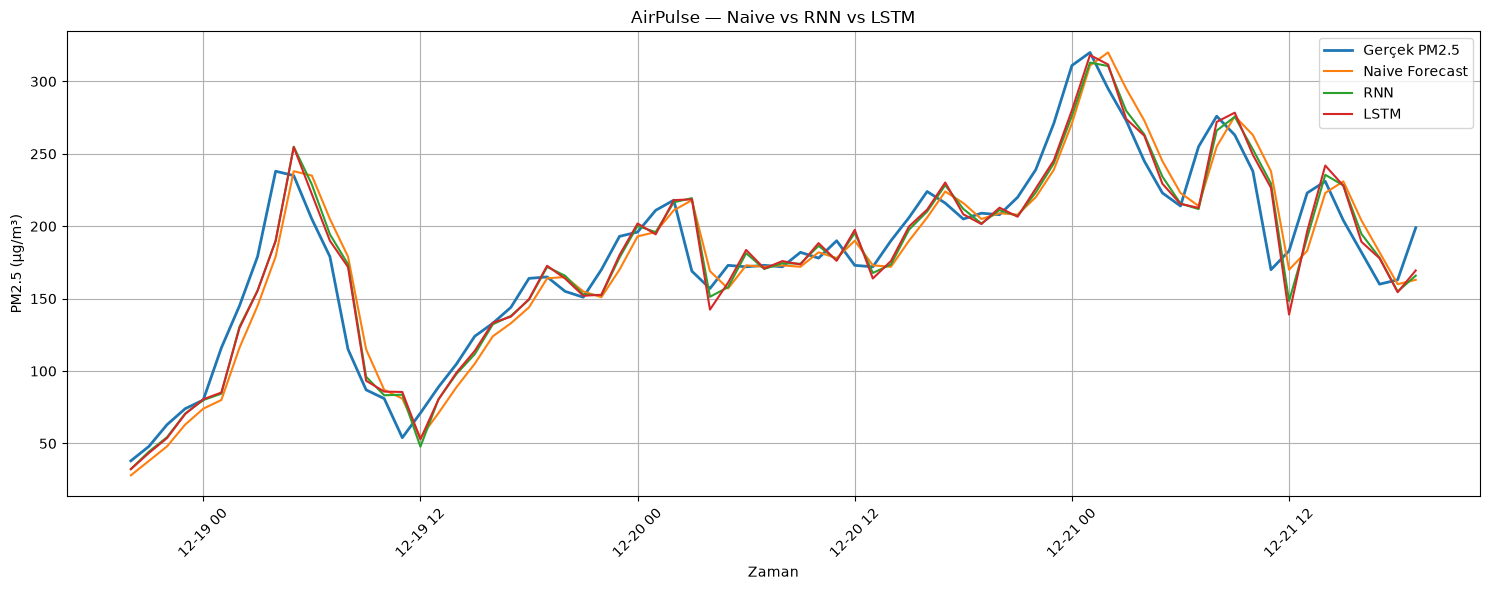

In [24]:
# 1. Validation zamanları ve gerçek değerler
times = pd.to_datetime(rnn["timestamps"])
actual = rnn["actual"]

# 2. Model tahminleri
rnn_predictions = rnn["predictions"]
lstm_predictions = lstm["predictions"]

# 3. Naive Forecast: Bir önceki saatin gerçek ölçümü
previous_times = times - pd.Timedelta(hours=1)

naive_predictions = (
    df_sorted.set_index("timestamp")["PM2.5"]
    .reindex(previous_times)
    .to_numpy()
)

assert not np.isnan(naive_predictions).any()

# 4. Validation döneminden 3 günlük aralık seç
start_time = times[0]
end_time = start_time + pd.Timedelta(days=3)

mask = (times >= start_time) & (times < end_time)

# 5. Grafik
plt.figure(figsize=(15, 6))

plt.plot(times[mask], actual[mask],
         label="Gerçek PM2.5", linewidth=2)

plt.plot(times[mask], naive_predictions[mask],
         label="Naive Forecast")

plt.plot(times[mask], rnn_predictions[mask],
         label="RNN")

plt.plot(times[mask], lstm_predictions[mask],
         label="LSTM")

plt.xlabel("Zaman")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("AirPulse — Naive vs RNN vs LSTM")

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

1. Üç model de genel eğilimi takip ediyor.

    PM2.5 yükseldiğinde tahminler de yükseliyor, düştüğünde düşüyor.

2. Ani yükselişlerde gecikme görüyoruz.

    Özellikle 19 Aralık ve 21 Aralık'taki yükselişlerde modeller gerçek değişimin biraz gerisinde kalabiliyor.
    Naive Forecast'in bir saat gecikmesi beklenen bir davranış. Çünkü doğrudan bir önceki saatin değerini tahmin olarak kullanıyor.

3. RNN ve LSTM birbirine oldukça yakın.

    Yeşil ve kırmızı çizgiler birçok noktada birbirine yakın olsa da artık birebir aynı değiller.
    Bu, iki modelin farklı tahminler ürettiğini gösteriyor.

4. Ani düşüşlerde de hatalar oluşuyor.

    Özellikle 21 Aralık civarındaki keskin düşüşlerde modellerin tahminleri gerçek değerden sapıyor.
    Bu grafik, modellerin hızlı değişimleri tahmin etmekte zorlanabildiğini gösteriyor.

Naive Forecast, RNN ve LSTM modelleri aynı 4.266 validation örneğinde karşılaştırılmıştır. Naive Forecast en düşük MAE değerini (10.37), LSTM ise en düşük RMSE değerini (20.78) elde etmiştir. Grafik incelemesinde üç modelin de genel PM2.5 eğilimini takip ettiği, ancak ani yükseliş ve düşüşlerde tahmin hatalarının oluştuğu gözlemlenmiştir. LSTM, RNN'e kıyasla sınırlı bir iyileşme sağlamıştır. Bu sonuçlar, daha karmaşık modellerin her zaman bütün değerlendirme metriklerinde üstün olmadığını göstermektedir.